# 19 - Induced errors: is there an error-related response over Fz / Cz?

**Hypothesis** (`experiment.md`): induced errors -- a genuine pinch that the system fails to register -- elicit an error-related potential over frontocentral electrodes (Fz, Cz).

**Which epochs are errors.** Two kinds of genuine pinch go unregistered, i.e. produce no selection and no visual/auditory feedback (`PinchHandler.HandlePinch` in the Unity project):
- **Ignored pinches** (`PinchType == 'PINCH_IGNORED'`): on induced-error trials `StimuliExperiment.cs` sets `hideNextPinch`, so the first pinch on the target is logged but suppressed and the participant has to pinch again.
- **Unregistered pinches** (`PinchType == 'PINCH'` and `EventName == 'PINCH_NONE'`): the hand tracker detected a pinch, but gaze was not confirmed on a stimulus, so nothing was selected (logged via `onPinchDetected` -> `new PinchLog()`).

Both count as errors here; the `error_type` metadata column keeps them apart. **Correct trials** are pinches that actually selected a stimulus (`EventName == 'PINCH_STIMULUS'`, `PinchType` `PINCH` or `PINCH_WIZARD_OF_OZ`) from the *same blocks* as the errors.

**Why new epochs.** The existing epoch datasets end 0.3 s after the pinch (`epoch_dataset_filtered`: -1.7 to 0.3 s), too short for an error response (N2/ERN ~200-350 ms, Pe/P3 ~300-500 ms after the expected feedback). This notebook re-epochs the fully cleaned continuous EEG in `data/annotated_dataset` (ICA-cleaned, 1-45 Hz, with `BAD_*` annotations; the same source `18_robust_epoching.ipynb` uses) from -0.5 to +1.0 s around each pinch. Nothing under `data/` is modified; outputs go to `out/`.

**Design choices (all to make error and correct trials differ only in the missing feedback):**
1. **Correct trials come from the same blocks as the errors**, and every participant's correct-trial average is **block-weighted** to the error trials' block distribution. This matches hinted vs. full pinches (most ignored pinches are in hinted blocks, whose registered counterpart is `PINCH_WIZARD_OF_OZ`, not `PINCH`), stimulus layout and feedback modality.
2. **The pinch right after an error is excluded from the correct trials** (it is a post-error trial).
3. **Overlapping movements are excluded**: the participant re-pinches a median of ~1.2-1.3 s after an error, and its readiness potential (a frontocentral negativity starting ~0.5-1 s before the movement) would otherwise contaminate the error window. Both conditions keep only pinches with no other pinch within `MIN_PREV_GAP` s before or `MIN_NEXT_GAP` s after.
4. **Delayed-feedback blocks are excluded** (their logged pinch time is shifted relative to the real pinch; see `11_preprocessing.ipynb`).
5. **Statistics at participant level** (the unit of replication): per-participant averages, then (a) a cluster-based permutation test on the error-minus-correct difference over 0-0.8 s at Fz and Cz, and (b) Wilcoxon signed-rank tests on the mean difference in the project's own ErrP windows (`errp_features` in `models/EEGForest.py`: N2 180-320 ms, P3 250-450 ms).

**Known limitation.** The "error" here is an *omission*: correct trials get visual/auditory feedback at the pinch, error trials get none. A feedback-evoked response in correct trials is therefore part of any difference, and the design cannot fully separate "error processing" from "absence of a feedback-evoked potential". See the interpretation at the end.

In [10]:
import pathlib, sys, os, json

ROOT = pathlib.Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Working directory:', pathlib.Path.cwd())

Working directory: C:\Users\nicol\github\VIBE\DataAnalysis


In [11]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import wilcoxon

mne.set_log_level('WARNING')

ANNOTATED_DATASET = ROOT / 'data' / 'annotated_dataset'
OUT_DIR = ROOT / 'out'
FIG_DIR = OUT_DIR / 'figs'
FIG_DIR.mkdir(parents=True, exist_ok=True)

TMIN, TMAX = -0.5, 1.0            # s around the pinch
BASELINE = (-0.2, 0.0)            # pre-feedback baseline (feedback is triggered by the registered pinch at t=0)
BAND = (1.0, 10.0)                # ErrP band, same as errp_features in models/EEGForest.py
REJECT = dict(eeg=150e-6)         # peak-to-peak rejection on top of the BAD_* annotations
MIN_PREV_GAP = 1.0                # s -- no other pinch in the second before
MIN_NEXT_GAP = 1.3                # s -- no other pinch until 1.3 s after (keeps the re-pinch's readiness potential out of 0-0.8 s)
MIN_ERR_EPOCHS = 3                # per participant, after rejection
TEST_WINDOW = (0.0, 0.8)          # s, cluster test range
ERRP_WINDOWS = {'N2': (0.18, 0.32), 'P3': (0.25, 0.45)}
CHANNELS = ['Fz', 'Cz']
N_PERMUTATIONS = 5000
SEED = 42

COLORS = {'correct': '#2a78d6', 'error': '#eb6834', 'diff': '#0b0b0b'}
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_red', ['#0d366b', '#f0efec', '#e34948'])

from scripts import paper_style  # two-column paper style for every figure (sizes/font in scripts/paper_style.py)
from scripts.paper_style import COL_W, TEXT_W, enforce_font_sizes

## Selecting error and correct pinches

For every session: all `PinchLog` rows (any type -- every pinch is a movement), their gap to the previous/next pinch, and the block (`ExperimentName`) they belong to. Errors are ignored (`PINCH_IGNORED`) and unregistered (`PINCH` + `PINCH_NONE`) pinches; `GAZE` selections (a highlighted-negative stimulus was selected) are neither.

In [12]:
manifest = json.load(open(ANNOTATED_DATASET / 'manifest.json'))

def session_pinches(subject, session):
    m = pd.read_parquet(ANNOTATED_DATASET / subject / session / manifest[subject][session]['markers']['file'])
    p = m[m['EventType'] == 'PinchLog'].sort_values('timestamp').reset_index(drop=True)
    p['prev_gap'] = p['timestamp'].diff()
    p['next_gap'] = -p['timestamp'].diff(-1)
    p['subject'], p['session'] = subject, session
    return p

pinches = pd.concat([session_pinches(s, ss) for s in sorted(manifest) for ss in sorted(manifest[s])],
                    ignore_index=True)
pinches['block'] = pinches['subject'] + '/' + pinches['session'] + '/' + pinches['ExperimentName']

is_ignored = pinches['PinchType'] == 'PINCH_IGNORED'
is_unregistered = (pinches['PinchType'] == 'PINCH') & (pinches['EventName'] == 'PINCH_NONE')
is_error = is_ignored | is_unregistered
# previous pinch in the same session was an error -> this one is a post-error trial
prev_is_error = is_error.groupby([pinches['subject'], pinches['session']]).shift(1, fill_value=False)
error_blocks = set(pinches.loc[is_error, 'block'])
is_correct = (pinches['PinchType'].isin(['PINCH', 'PINCH_WIZARD_OF_OZ'])
              & (pinches['EventName'] == 'PINCH_STIMULUS')                 # actually selected a stimulus
              & pinches['block'].isin(error_blocks)
              & ~prev_is_error)
isolated = ((pinches['prev_gap'].fillna(np.inf) >= MIN_PREV_GAP)
            & (pinches['next_gap'].fillna(np.inf) >= MIN_NEXT_GAP))
not_delayed = ~pinches['feedbackIsDelayed'].astype(bool)

pinches['condition'] = np.where(is_error, 'error', np.where(is_correct, 'correct', None))
pinches['error_type'] = np.where(is_ignored, 'ignored', np.where(is_unregistered, 'unregistered', None))
pinches['isolated'] = isolated
# candidates for both the main analysis (isolated only) and the sensitivity analysis (all)
candidates = pinches[pinches['condition'].notna() & not_delayed].copy()

print('all errors:', int(is_error.sum()), f'(ignored: {int(is_ignored.sum())}, unregistered: {int(is_unregistered.sum())})')
print(pd.crosstab([candidates['condition'], candidates['isolated']],
                  [candidates['PinchType'], candidates['EventName']], margins=True).to_string())

all errors: 650 (ignored: 373, unregistered: 277)
PinchType               PINCH                 PINCH_IGNORED PINCH_WIZARD_OF_OZ   All
EventName          PINCH_NONE PINCH_STIMULUS PINCH_STIMULUS     PINCH_STIMULUS      
condition isolated                                                                  
correct   False             0             16              0                104   120
          True              0           1480              0                364  1844
error     False           144              0            197                  0   341
          True             83              0            128                  0   211
All                       227           1496            325                468  2516


## Epoching

Per session: band-pass the cleaned continuous EEG to 1-10 Hz, epoch -0.5 to +1.0 s around every candidate pinch, baseline -0.2 to 0 s, and drop epochs touching a `BAD_*` annotation or exceeding 150 µV peak-to-peak. The mastoid channels A1/A2 are dropped. All candidates are epoched once; the `isolated` metadata column selects the main-analysis subset.

In [13]:
epochs_list = []
for (subject, session), sel in candidates.groupby(['subject', 'session']):
    raw = mne.io.read_raw_fif(ANNOTATED_DATASET / subject / session / manifest[subject][session]['eeg']['file'],
                              preload=True)
    raw.drop_channels([c for c in ('A1', 'A2') if c in raw.ch_names])
    raw.filter(*BAND, method='iir')
    samples = np.round(sel['timestamp'].to_numpy() * raw.info['sfreq']).astype(int) + raw.first_samp
    events = np.column_stack([samples, np.zeros_like(samples), (sel['condition'] == 'error').astype(int)])
    md_sel = sel[['subject', 'session', 'block', 'condition', 'error_type', 'PinchType', 'EventName',
                  'isolated', 'timestamp']]
    ep = mne.Epochs(raw, events, event_id={'correct': 0, 'error': 1}, tmin=TMIN, tmax=TMAX,
                    baseline=BASELINE, reject=REJECT, reject_by_annotation=True,
                    metadata=md_sel.reset_index(drop=True), preload=True, on_missing='ignore')
    epochs_list.append(ep)
    del raw

epochs = mne.concatenate_epochs(epochs_list)
md = epochs.metadata.reset_index(drop=True)
times = epochs.times
ch_names = epochs.ch_names
data = epochs.get_data() * 1e6  # (n_epochs, n_channels, n_times), µV

kept = md.groupby(['condition', 'isolated']).size()
total = candidates.groupby(['condition', 'isolated']).size()
print(pd.DataFrame({'candidates': total, 'kept_after_rejection': kept}).fillna(0).astype(int).to_string())

                    candidates  kept_after_rejection
condition isolated                                  
correct   False            120                    76
          True            1844                  1156
error     False            341                   194
          True             211                   133


C:\Users\nicol\AppData\Local\Temp\ipykernel_27920\2076944826.py:17: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs = mne.concatenate_epochs(epochs_list)


## Participant-level averages

Error trials: plain per-participant average. Correct trials: per-block averages, weighted by how many error trials that participant has in each block (so both conditions have the same block mix). Participants with fewer than `MIN_ERR_EPOCHS` error epochs, or with an error block that has no correct epoch, are dropped.

In [14]:
def participant_averages(subset_md):
    '''(error, correct, ids, counts): per-participant error average and block-weighted correct average,
    each (n_subjects, n_channels, n_times), for the epochs in `subset_md` (rows of `md`).'''
    err_avgs, cor_avgs, ids, counts = [], [], [], []
    for subject, g in subset_md.groupby('subject'):
        err_idx = g.index[g['condition'] == 'error']
        if len(err_idx) < MIN_ERR_EPOCHS:
            continue
        w = g.loc[err_idx, 'block'].value_counts()
        block_means = {}
        for b in w.index:
            cor_idx = g.index[(g['condition'] == 'correct') & (g['block'] == b)]
            if len(cor_idx) == 0:
                break
            block_means[b] = data[cor_idx].mean(0)
        if len(block_means) < len(w):
            continue
        err_avgs.append(data[err_idx].mean(0))
        cor_avgs.append(sum(w[b] * block_means[b] for b in w.index) / w.sum())
        ids.append(subject)
        counts.append((len(err_idx), int((g['condition'] == 'correct').sum())))
    return np.array(err_avgs), np.array(cor_avgs), ids, counts


subj_err, subj_cor, subj_ids, subj_n = participant_averages(md[md['isolated']])
subj_diff = subj_err - subj_cor
n_subj = len(subj_ids)
print(f'{n_subj} participants; (error, correct) epochs per participant:', dict(zip(subj_ids, subj_n)))
excluded = sorted(set(md['subject']) - set(subj_ids))
print('excluded (fewer than', MIN_ERR_EPOCHS, 'error epochs or an error block without correct epochs):', excluded)

12 participants; (error, correct) epochs per participant: {'subject_23': (10, 84), 'subject_24': (17, 73), 'subject_25': (6, 91), 'subject_26': (6, 75), 'subject_28': (9, 73), 'subject_30': (6, 75), 'subject_32': (7, 75), 'subject_33': (21, 119), 'subject_34': (8, 95), 'subject_35': (14, 109), 'subject_36': (3, 5), 'subject_37': (16, 106)}
excluded (fewer than 3 error epochs or an error block without correct epochs): ['subject_21', 'subject_22', 'subject_27', 'subject_29']


## Statistics

(a) Cluster-based permutation test (sign-flip, two-tailed, 5000 permutations) on the per-participant error-minus-correct difference at Fz and at Cz, over 0-0.8 s. (b) Wilcoxon signed-rank test on the mean difference in the N2 and P3 windows (4 tests; Bonferroni-corrected p reported alongside).

In [15]:
def errp_stats(diff):
    '''Cluster permutation test per channel + Wilcoxon window tests on per-participant differences.'''
    test_mask = (times >= TEST_WINDOW[0]) & (times <= TEST_WINDOW[1])
    test_times = times[test_mask]
    clusters = {}
    for ch in CHANNELS:
        X = diff[:, ch_names.index(ch), test_mask]
        t_obs, cl, cl_p, _ = mne.stats.permutation_cluster_1samp_test(
            X, n_permutations=N_PERMUTATIONS, tail=0, seed=SEED, out_type='mask', verbose=False)
        clusters[ch] = [(float(test_times[c][0]), float(test_times[c][-1]), float(p),
                         'negative' if t_obs[c].mean() < 0 else 'positive') for c, p in zip(cl, cl_p)]
    rows = []
    for ch in CHANNELS:
        ci = ch_names.index(ch)
        for name, (a, b) in ERRP_WINDOWS.items():
            d = diff[:, ci, (times >= a) & (times <= b)].mean(1)
            stat, p = wilcoxon(d)
            rows.append(dict(channel=ch, window=f'{name} {int(a * 1000)}-{int(b * 1000)} ms',
                             mean_diff_uv=d.mean(), sem_uv=d.std(ddof=1) / np.sqrt(len(d)),
                             n_negative=int((d < 0).sum()), n_subjects=len(d),
                             wilcoxon_W=stat, p_value=p, p_bonferroni=min(1.0, p * 4)))
    return clusters, pd.DataFrame(rows)


def print_clusters(clusters):
    for ch, cl in clusters.items():
        print(f'{ch}:', '; '.join(f'{a:.3f}-{b:.3f} s {sign} (p={p:.4f})' for a, b, p, sign in cl) or 'no clusters')


clusters, win_df = errp_stats(subj_diff)
win_df.to_csv(OUT_DIR / 'induced_error_errp_windows.csv', index=False)
print_clusters(clusters)
print()
print(win_df.round(4).to_string())

Fz: 0.533-0.600 s positive (p=0.1187); 0.267-0.393 s negative (p=0.0225); 0.637-0.720 s negative (p=0.0293)
Cz: 0.510-0.610 s positive (p=0.0093); 0.000-0.000 s negative (p=0.6455); 0.280-0.417 s negative (p=0.0093); 0.643-0.713 s negative (p=0.0547)

  channel         window  mean_diff_uv  sem_uv  n_negative  n_subjects  wilcoxon_W  p_value  p_bonferroni
0      Fz  N2 180-320 ms       -2.1241  1.0274           8          12        15.0   0.0640        0.2559
1      Fz  P3 250-450 ms       -2.6447  1.0128          10          12         8.0   0.0122        0.0488
2      Cz  N2 180-320 ms       -0.6547  0.6771           7          12        26.0   0.3394        1.0000
3      Cz  P3 250-450 ms       -1.4280  0.4469          10          12         6.0   0.0068        0.0273


## Figure

Top: grand-average ERP (mean +/- SEM across participants) for induced errors vs. correct (registered) pinches at Fz and Cz. Bottom: the error-minus-correct difference wave; shaded spans are clusters with p < 0.05 from the permutation test, grey bands the N2/P3 windows. Right: scalp maps of the difference in the N2 and P3 windows.

Wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\induced_error_errp.pdf


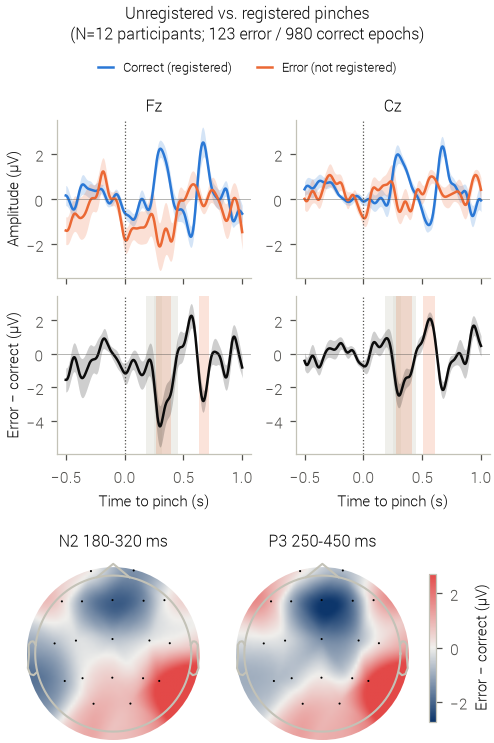

In [16]:
def mean_sem(x):
    return x.mean(0), x.std(0, ddof=1) / np.sqrt(len(x))

fig = plt.figure(figsize=(COL_W, 5.0), layout='constrained')
# separate subfigures, so the topomap colorbar does not narrow the line plots above it
sf_lines, sf_topo = fig.subfigures(2, 1, height_ratios=[2.1, 1])
gs = sf_lines.add_gridspec(2, 2)
erp_axes = [sf_lines.add_subplot(gs[0, i]) for i in range(2)]
diff_axes = [sf_lines.add_subplot(gs[1, i], sharex=erp_axes[i]) for i in range(2)]
for ax in erp_axes[1:]:
    ax.sharey(erp_axes[0])
for ax in diff_axes[1:]:
    ax.sharey(diff_axes[0])

for i, ch in enumerate(CHANNELS):
    ci = ch_names.index(ch)
    ax = erp_axes[i]
    for cond, arr in (('correct', subj_cor), ('error', subj_err)):
        m, s = mean_sem(arr[:, ci])
        label = 'Correct (registered)' if cond == 'correct' else 'Error (not registered)'
        ax.plot(times, m, color=COLORS[cond], linewidth=1.2, label=label)
        ax.fill_between(times, m - s, m + s, color=COLORS[cond], alpha=0.2, linewidth=0)
    ax.set_title(ch)
    ax.tick_params(labelbottom=False)

    ax = diff_axes[i]
    for name, (a, b) in ERRP_WINDOWS.items():
        ax.axvspan(a, b, color='#e1e0d9', alpha=0.5, linewidth=0)
    for a, b, p, _ in clusters[ch]:
        if p < 0.05:
            ax.axvspan(a, b, color=COLORS['error'], alpha=0.18, linewidth=0)
    m, s = mean_sem(subj_diff[:, ci])
    ax.plot(times, m, color=COLORS['diff'], linewidth=1.2)
    ax.fill_between(times, m - s, m + s, color=COLORS['diff'], alpha=0.2, linewidth=0)
    ax.set_xlabel('Time to pinch (s)')

for ax in erp_axes + diff_axes:
    ax.axvline(0, color='#52514e', linewidth=0.6, linestyle=':')
    ax.axhline(0, color='#52514e', linewidth=0.4, alpha=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
erp_axes[0].set_ylabel('Amplitude (µV)')
diff_axes[0].set_ylabel('Error − correct (µV)')
sf_lines.legend(*erp_axes[0].get_legend_handles_labels(), loc='outside upper center', ncols=2, frameon=False, handlelength=1.2)

# topomaps of the difference in the two ErrP windows, shared symmetric color scale
info = epochs.copy().pick('eeg').info
maps = {name: subj_diff[:, :, (times >= a) & (times <= b)].mean((0, 2)) for name, (a, b) in ERRP_WINDOWS.items()}
vmax = max(np.abs(v).max() for v in maps.values())
topo_axes = list(sf_topo.subplots(1, 2))
for ax, (name, v) in zip(topo_axes, maps.items()):
    im, _ = mne.viz.plot_topomap(v, info, axes=ax, show=False, cmap=DIV_CMAP, vlim=(-vmax, vmax),
                                 sensors=True, contours=0)
    a, b = ERRP_WINDOWS[name]
    ax.set_title(f'{name} {int(a*1000)}-{int(b*1000)} ms')
cbar = sf_topo.colorbar(im, ax=topo_axes, shrink=0.8, location='right')
cbar.set_label('Error − correct (µV)')

n_err_total = int(sum(n[0] for n in subj_n))
n_cor_total = int(sum(n[1] for n in subj_n))
fig.suptitle(f'Unregistered vs. registered pinches\n(N={n_subj} participants; '
             f'{n_err_total} error / {n_cor_total} correct epochs)')
enforce_font_sizes(fig)
fig_path = FIG_DIR / 'induced_error_errp.pdf'
fig.savefig(fig_path)
print('Wrote', fig_path)
plt.show()

## Sensitivity: without the isolation filter

The isolation filter removes 62% of the error trials (the re-pinch often follows within 1.3 s); together with artifact rejection this drops 4 of 16 participants. Re-running the same statistics on *all* non-delayed error/correct pinches shows how much the result depends on it. Without the filter, overlapping movements (the re-pinch and its own feedback) fall inside the epoch, so this is a robustness check, not a cleaner estimate.

In [17]:
sens_err, sens_cor, sens_ids, sens_n = participant_averages(md)
sens_clusters, sens_win_df = errp_stats(sens_err - sens_cor)
sens_win_df.to_csv(OUT_DIR / 'induced_error_errp_windows_no_isolation.csv', index=False)
print(f'{len(sens_ids)} participants, {sum(n[0] for n in sens_n)} error / {sum(n[1] for n in sens_n)} correct epochs')
print_clusters(sens_clusters)
print()
print(sens_win_df.round(4).to_string())

14 participants, 309 error / 1134 correct epochs
Fz: 0.490-0.567 s positive (p=0.0570); 0.277-0.333 s negative (p=0.0972); 0.650-0.723 s negative (p=0.0302)
Cz: 0.507-0.603 s positive (p=0.0152); 0.277-0.333 s negative (p=0.1030); 0.667-0.723 s negative (p=0.1384)

  channel         window  mean_diff_uv  sem_uv  n_negative  n_subjects  wilcoxon_W  p_value  p_bonferroni
0      Fz  N2 180-320 ms       -0.6089  0.6986           8          14        40.0   0.4631        1.0000
1      Fz  P3 250-450 ms       -0.8894  0.6664          10          14        28.0   0.1353        0.5410
2      Cz  N2 180-320 ms       -0.6123  0.5386           7          14        38.0   0.3910        1.0000
3      Cz  P3 250-450 ms       -1.0071  0.3918          10          14        16.0   0.0203        0.0811


## Sensitivity: each error type on its own

Ignored and unregistered pinches are pooled above. They are not identical situations: an ignored pinch was aimed at the confirmed target, while an unregistered pinch happened without confirmed gaze on any stimulus (so the participant may have noticed they were not looking at a target). The same window tests, restricted to one error type at a time (isolated epochs; all correct epochs from the same blocks), show whether both contribute the same effect.

In [18]:
type_rows = []
for etype in ('ignored', 'unregistered'):
    sub = md[md['isolated'] & ((md['condition'] == 'correct') | (md['error_type'] == etype))]
    e, c, ids, n = participant_averages(sub)
    if len(ids) < 5:
        print(f'{etype}: only {len(ids)} participants with >= {MIN_ERR_EPOCHS} error epochs, skipped')
        continue
    _, wdf = errp_stats(e - c)
    wdf.insert(0, 'error_type', etype)
    wdf['n_error_epochs'] = sum(x[0] for x in n)
    type_rows.append(wdf)
type_df = pd.concat(type_rows, ignore_index=True)
type_df.to_csv(OUT_DIR / 'induced_error_errp_windows_by_error_type.csv', index=False)
print(type_df.round(4).to_string())

     error_type channel         window  mean_diff_uv  sem_uv  n_negative  n_subjects  wilcoxon_W  p_value  p_bonferroni  n_error_epochs
0       ignored      Fz  N2 180-320 ms       -2.0203  0.8699           9          11        10.0   0.0420        0.1680              74
1       ignored      Fz  P3 250-450 ms       -2.3664  0.6768          10          11         5.0   0.0098        0.0391              74
2       ignored      Cz  N2 180-320 ms       -0.6795  0.7969           6          11        24.0   0.4648        1.0000              74
3       ignored      Cz  P3 250-450 ms       -1.4475  0.5002          10          11         4.0   0.0068        0.0273              74
4  unregistered      Fz  N2 180-320 ms       -1.7397  1.8644           4           7        10.0   0.5781        1.0000              45
5  unregistered      Fz  P3 250-450 ms       -2.2982  2.4413           4           7        10.0   0.5781        1.0000              45
6  unregistered      Cz  N2 180-320 ms       -0.

C:\Users\nicol\AppData\Local\Temp\ipykernel_27920\2673492332.py:8: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  t_obs, cl, cl_p, _ = mne.stats.permutation_cluster_1samp_test(


## Interpretation

**Can the epochs test the hypothesis?** Yes, with caveats. The existing epoch datasets cannot (they end 0.3 s after the pinch), but re-epoching the cleaned continuous data around the error markers can. The comparison is limited by (a) few error trials -- 123 usable isolated error epochs from 12 participants (3-21 each), 4 participants excluded -- and (b) the omission design (below).

**Result.** Unregistered pinches differ from registered ones over frontocentral electrodes: the error-minus-correct difference is negative from about 270 to 410 ms after the pinch at Fz (cluster p = 0.023) and Cz (cluster p = 0.009), with a frontal maximum in the scalp maps. In the project's ErrP windows, the P3-window (250-450 ms) difference survives Bonferroni correction at both electrodes (Fz -2.6 µV, p = 0.049; Cz -1.4 µV, p = 0.027; 10 of 12 participants negative at each); the N2 window is not significant. Later clusters follow (Cz positive 510-610 ms, p = 0.009; Fz negative 640-720 ms, p = 0.029), giving an alternating negative-positive-negative pattern.

**Robustness.** The effect is carried by the ignored pinches: on their own they reproduce it (Fz P3 -2.4 µV, p = 0.039; Cz P3 -1.4 µV, p = 0.027, Bonferroni, 11 participants). Unregistered (`PINCH_NONE`) pinches point the same way with a similar mean (Fz P3 -2.3 µV) but only 7 participants have enough of them and they vary widely, so they are not significant alone. Without the isolation filter (14 participants, overlapping movements included) the window effects shrink and are no longer significant after correction (Cz P3 p = 0.08), so the result depends on keeping the re-pinch out of the epoch.

**What this does and does not show.** The hypothesis cannot be dismissed: there is a reliable frontocentral difference in the expected time range. It is not, however, clean evidence for an *error-related potential*:
- The top panels show the difference is driven mainly by a positive deflection around 250-400 ms in the *correct* trials -- a feedback-evoked response to the visual/auditory confirmation -- which is absent after unregistered pinches. Because the error is an *omission* of feedback, "error processing" and "no feedback-evoked potential" predict the same difference, and this design cannot separate them.
- At Fz the error trials already differ before the pinch (about -1.5 µV around -0.5 s, before the -0.2-0 s baseline), so error and correct trials are not fully equivalent beforehand; for unregistered pinches this is plausible, since gaze was not on a target.

**What would separate them.** A condition in which correct pinches also receive no feedback, or error trials with *wrong* (rather than missing) feedback. Within the existing data, the closest control is the delayed-feedback trials: for the first 0.5 s they also lack feedback at the expected moment. If errors and delayed-feedback trials do not differ before the delayed feedback arrives, the frontocentral difference is best described as an omission (missing-feedback) response rather than an error-specific one.